In [1]:
from vpython import *
from math import *
import random
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import gspread
import os

/opt/anaconda3/envs/vPythonEnv/lib/python3.10/site-packages/vpython/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


<IPython.core.display.Javascript object>

Periodic Boundary Capture and Time to Total Death

In [2]:
WallL = box(pos=vector(-10,0,0),size=vector(.2,20,5),color=color.red)
WallR = box(pos=vector(10,0,0),size=vector(.2,20,5),color=color.red)
Wall_top = box(pos=vector(0,10,0),size=vector(20,.2,5),color=color.red)
Wall_bottom = box(pos=vector(0,-10,0),size=vector(20,.2,5),color=color.red)
Wall_front = box(pos=vector(0,0,2.5),size=vector(20,20,0.2),color=color.red,opacity=0.1)
Wall_back = box(pos=vector(0,0,-2.5),size=vector(20,20,0.2),color=color.red,opacity=0.1)
#
n = []
num_died = []
n_particles = 100
for i in range(n_particles):
    x = random.randint(-9,9)
    y = random.randint(-9,9)
    z = random.randint(-2,2)
    vx = random.randint(-3,3)
    vy = random.randint(-3,3)
    vz = random.randint(-3,3)
    carbon = sphere(pos=vector(x,y,z),color=color.cyan,radius=0.25)
    carbon.velocity = vector(vx,vy,vz)
    n.append(carbon)
#
# use compound function to create a more realistic MOF?
#
MOF = sphere(pos=vector(0,0,0),radius=1,color=color.red)
#
MOF.velocity = vector(0.4,0.2,0.5)
#
timeplot = graph(title='Time to Death',xtitle='Time',ytitle='Number Died',xmin=0,
                   xmax=1000, ymin=0,ymax=100)
#
drawTimeDeath = gcurve(color=color.red,label='Time')
#
dead = 0
total_dead = sum(item.radius == 0 for item in n)
#
tlist = []
# to store t with this list
t = 0
dt = 0.1
#
while t<200:
    rate(100)
    for item in n: 
        if item.visible:
            item.pos = item.pos + item.velocity*dt
        if item.pos.x <= WallL.pos.x:
            item.velocity.x = -item.velocity.x
        if item.pos.x >= WallR.pos.x:
            item.velocity.x = -item.velocity.x
        if item.pos.y >= Wall_top.pos.y:
            item.velocity.y = -item.velocity.y
        if item.pos.y <= Wall_bottom.pos.y:
            item.velocity.y = -item.velocity.y
        if item.pos.z >= Wall_front.pos.z:
            item.velocity.z = -item.velocity.z
        if item.pos.z <= Wall_back.pos.z:
            item.velocity.z = -item.velocity.z
        if mag(item.pos - MOF.pos) <= item.radius + MOF.radius:
            item.visible = False
#
        if MOF.visible:
            MOF.pos = MOF.pos + MOF.velocity*dt
        if MOF.pos.x <= WallL.pos.x:
            MOF.velocity.x = -MOF.velocity.x
        if MOF.pos.x >= WallR.pos.x:
            MOF.velocity.x = -MOF.velocity.x
        if MOF.pos.y >= Wall_top.pos.y:
            MOF.velocity.y = -MOF.velocity.y
        if MOF.pos.y <= Wall_bottom.pos.y:
            MOF.velocity.y = -MOF.velocity.y
        if MOF.pos.z + MOF.radius >= Wall_front.pos.z:
            MOF.velocity.z = -abs(MOF.velocity.z)
        if MOF.pos.z - MOF.radius <= Wall_back.pos.z:
            MOF.velocity.z = abs(MOF.velocity.z)
#
    for item in n:
        if item.visible == False:
            item.radius = dead
        #if sum(item.radius == 0 for item in n) == n_particles:
            #print('Time of Death',t,'seconds')
    num_died.append(sum(item.radius == 0 for item in n))
    tlist.append(t)
    drawTimeDeath.plot(pos=(t,sum(item.radius == 0 for item in n)))
    t = t+dt
#

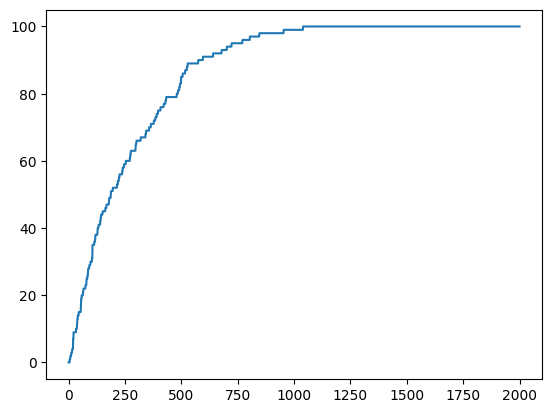

In [3]:
plt.plot(num_died)

--- Unbounded Fit ---
c: 101.009 (Expected ~100)
a: 28.151 (Expected ~250)

---Bounded Fit---
c: 101.009 (Expected ~100)
a: 28.151 (Expected ~250



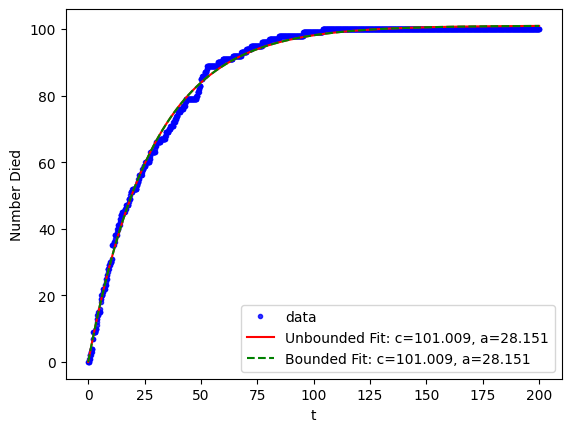

In [4]:
#
#defining initial function a(1-e^-t/c) c and a are flipped though
#
def func(t, c, a):
    return c * (1 - (np.exp(-t/a)))
#
#defining initial parameters
#
xdata = np.array(tlist)
ydata = np.array(num_died)
plt.plot(xdata, ydata, 'b.', alpha = 0.8, label='data')
popt, pcov = curve_fit(func, xdata, ydata, p0=[50,100])
#
#unbounded fit,sources from popt array,plots a red line - no bounds like in the next part where we constrain fit within reasonable values
#
print("--- Unbounded Fit ---")
print(f"c: {popt[0]:.3f} (Expected ~100)")
print(f"a: {popt[1]:.3f} (Expected ~250)\n")
plt.plot(xdata, func(xdata, *popt), 'r-',
         label=f'Unbounded Fit: c={popt[0]:.3f}, a={popt[1]:.3f}')
#
#defining the bounds for bounded fit, same code as before but just adding bounds
#
lower_bound = [0,0]
upper_bound = [250,500]
popt_bound, pcov_bound = curve_fit(func, xdata, ydata, p0=[50,100], bounds=(lower_bound,upper_bound))
#
#coding the bounded fit, green dashed line within bounds so the optimization might look slightly different 
#
print("---Bounded Fit---")
print(f"c: {popt[0]:.3f} (Expected ~100)")
print(f"a: {popt[1]:.3f} (Expected ~250\n")
plt.plot(xdata, func(xdata, *popt_bound), 'g--',
         label=f'Bounded Fit: c={popt_bound[0]:.3f}, a={popt_bound[1]:.3f}')
#
#plotting the final graph and making it show
#
plt.xlabel('t')
plt.ylabel('Number Died')
plt.legend()
plt.show()

In [5]:
try:
    from google.colab import auth
    auth.authenticate_user()
    from google.auth import default
    creds, _ = default()
    gc = gspread.authorize(creds)
    print("Authenticated via Google Colab natively.")
except ModuleNotFoundError:
    # LOCAL FIX: Use the physical JSON file sitting in your folder
    key_file = 'secret-key.json'
    
    if os.path.exists(key_file):
        gc = gspread.service_account(filename=key_file)
        print("Successfully authenticated locally using your service account key!")
    else:
        raise FileNotFoundError(f"❌ Error: Could not find '{key_file}' in your current directory ({os.getcwd()}). Please place it there.")
# 
import datetime
#
spreadsheet = gc.open('Decay Rate Output')
worksheet = spreadsheet.sheet1
#
existing_ids = worksheet.col_values(2)
data_row_count = len(existing_ids)
# 2. Automatically determine the next ID number
if data_row_count == 0:
    next_number = 1
else:
    next_number = data_row_count  # If there is 1 header and 1 data row, len is 2, so next is ID 2
#simulation ID 
simulation_id = f"DecayRate_{next_number:02d}"
#calculate decay rate
decay_rate = round(float(popt[1]),3)
#timestamp
timestamp = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
#append
worksheet.append_row([timestamp, simulation_id, decay_rate])
print(f"✓ Successfully appended: {simulation_id} -> {decay_rate}")

Successfully authenticated locally using your service account key!
✓ Successfully appended: DecayRate_07 -> 28.151
